# Network Analytics for Portfolio Construction (refactored)

Active managers try to beat an index such as the S&P 500. Here we use **network analytics** to pick two baskets of stocks and compare them with the index over 2021:

- **Central portfolio** – stocks that sit at the core of the correlation network.
- **Peripheral portfolio** – stocks that sit at the edge of the network.

Method follows [Dynamic portfolio strategy using clustering approach](https://arxiv.org/pdf/1608.03058.pdf).

**Approach**
1. Load daily prices for S&P 500 constituents (2011–2020) and compute log returns.
2. Build a correlation matrix, convert it to a distance matrix and filter it with a Minimum Spanning Tree (MST).
3. Track how the network changes year by year (average shortest path length).
4. On the full 2011–2020 MST, rank stocks by degree/betweenness centrality and by three distance criteria.
5. Pick the 15 most central and 15 most peripheral stocks, invest 100,000 in each from 2021-01-04, and compare with the S&P 500.

**Data** (same files as the original notebook): `snp500_price_data_2011_to_2020.csv`, `snp500_price_data_2021.csv`, and the S&P 500 index level from FRED (downloaded once, then cached in `sp500_index_2021.csv`).

**What changed vs. the original notebook**
- No Wikipedia scraping or `pandas_datareader` – the tickers are already the CSV columns, and the index comes straight from FRED. Both were fragile.
- Ten copy-pasted per-year blocks are now dictionaries/loops.
- Log returns use the conventional sign, `log(P_t) - log(P_{t-1})` (correlations/MST are unaffected by the sign).
- Portfolios are **equal-dollar weighted** per stock. The original summed raw share prices, which silently over-weighted expensive stocks.

## 1. Setup

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import seaborn as sns
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

DATA_DIR = Path('.')
PRICES_2011_2020 = DATA_DIR / 'snp500_price_data_2011_to_2020.csv'
PRICES_2021 = DATA_DIR / 'snp500_price_data_2021.csv'
SP500_CACHE = DATA_DIR / 'sp500_index_2021.csv'
FRED_URL = 'https://fred.stlouisfed.org/graph/fredgraph.csv?id=SP500'

YEARS = list(range(2011, 2021))
N_STOCKS = 15            # stocks per portfolio
INVESTMENT = 100_000     # starting capital per portfolio

## 2. Load price data

In [2]:
prices = pd.read_csv(PRICES_2011_2020, index_col=0, parse_dates=True)
prices_2021 = pd.read_csv(PRICES_2021, index_col=0, parse_dates=True)
print('2011-2020:', prices.shape, '| 2021:', prices_2021.shape)
prices.head()

2011-2020: (2518, 505) | 2021: (253, 505)


,MMM,AOS,ABT,ABBV,ABMD,ACN,ATVI,ADM,ADBE,ADP,...,XEL,XLNX,XYL,YUM,ZBRA,ZBH,ZION,ZTS,CEG,OGN
Date,,,,,,,,,,,,,,,,,,,,,
2010-12-31,63.855606,8.113162,17.986767,NaN,9.61,39.143620,11.245819,22.385578,30.780001,31.271172,...,16.221039,23.216919,NaN,28.547478,37.990002,49.212429,21.089169,NaN,NaN,NaN
2011-01-03,64.218163,8.125947,17.952976,NaN,9.80,39.224346,11.318138,22.623722,31.290001,31.791464,...,16.227924,23.569420,NaN,28.570745,38.200001,50.395058,21.907326,NaN,NaN,NaN
2011-01-04,64.129395,8.100383,18.121916,NaN,9.80,38.966022,11.327178,22.608845,31.510000,31.676586,...,16.296804,23.665552,NaN,28.134232,37.840000,49.725819,21.550467,NaN,NaN,NaN
2011-01-05,64.129395,8.285738,18.121916,NaN,10.03,38.974094,11.110217,22.713020,32.220001,32.183357,...,16.200367,23.745670,NaN,28.268110,37.799999,49.762482,21.672325,NaN,NaN,NaN
2011-01-06,63.737186,8.289999,18.084377,NaN,10.05,39.119389,11.083097,23.583750,32.270000,32.433369,...,16.186602,24.146229,NaN,28.465996,37.480000,48.222305,21.611391,NaN,NaN,NaN


### Missing data due to index rebalancing
Stocks that joined the index part-way through the period have missing history. Dark cells below are missing values.

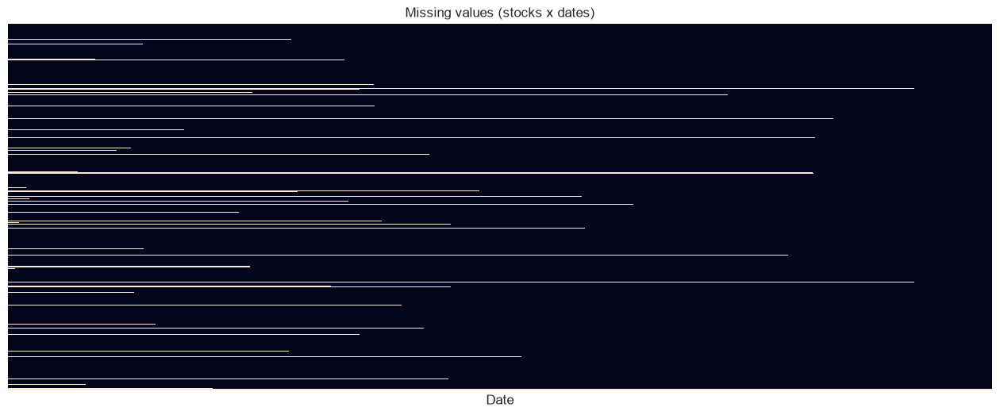

In [3]:
fig, ax = plt.subplots(figsize=(16, 6))
sns.heatmap(prices.T.isnull(), cbar=False, xticklabels=False, yticklabels=False, ax=ax)
ax.set_title('Missing values (stocks x dates)');

In [4]:
# Keep only stocks with a complete history over the whole period
prices_clean = prices.dropna(axis=1)
print(f'Kept {prices_clean.shape[1]} of {prices.shape[1]} stocks')

Kept 450 of 505 stocks


## 3. Log returns, correlation and distance

In [5]:
def log_returns(p):
    return np.log(p).diff().dropna(how='all')

returns = log_returns(prices_clean)

def correlation_to_distance(corr):
    # Mantegna distance: 0 for perfectly correlated, 2 for perfectly anti-correlated
    return np.sqrt(2 * (1 - corr))

returns_by_year = {y: returns.loc[str(y)] for y in YEARS}
corr_by_year = {y: r.corr() for y, r in returns_by_year.items()}

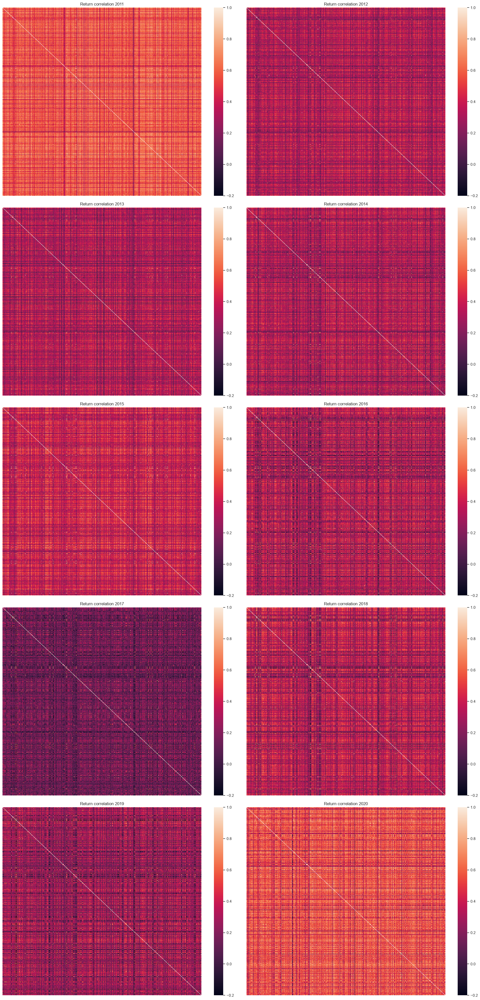

In [6]:
fig, axes = plt.subplots(5, 2, figsize=(20, 40))
for ax, y in zip(axes.ravel(), YEARS):
    sns.heatmap(corr_by_year[y], ax=ax, xticklabels=False, yticklabels=False, vmin=-0.2, vmax=1)
    ax.set_title(f'Return correlation {y}')
plt.tight_layout();

## 4. Network and Minimum Spanning Tree
The full correlation graph is a dense hairball. The MST keeps only the N-1 edges that connect all stocks with the smallest total distance.

In [7]:
def build_mst(corr):
    dist = correlation_to_distance(corr)
    graph = nx.from_pandas_adjacency(dist)
    graph.remove_edges_from(nx.selfloop_edges(graph))   # zero-distance diagonal
    return nx.minimum_spanning_tree(graph)

mst_by_year = {y: build_mst(c) for y, c in corr_by_year.items()}
print({y: g.number_of_edges() for y, g in mst_by_year.items()})

{2011: 449, 2012: 449, 2013: 449, 2014: 449, 2015: 449, 2016: 449, 2017: 449, 2018: 449, 2019: 449, 2020: 449}


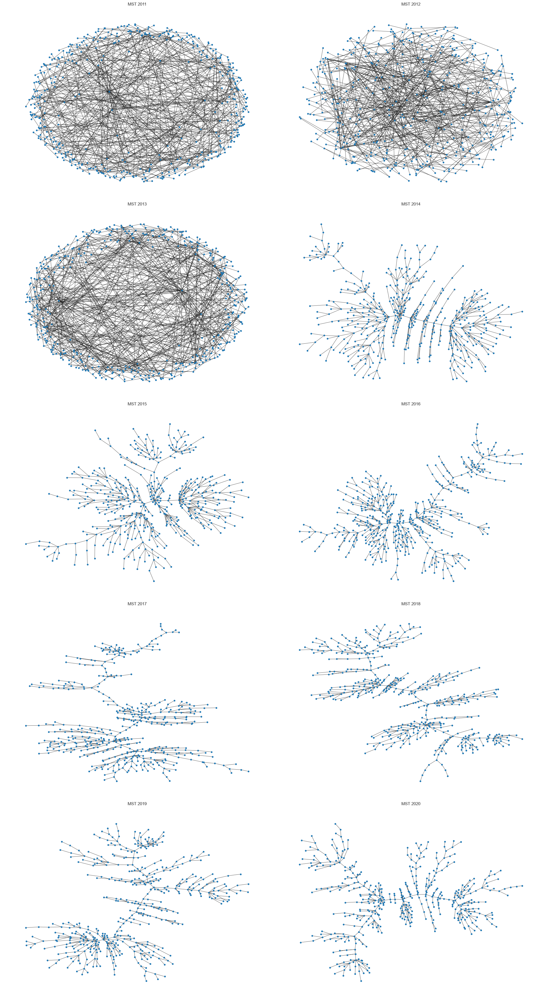

In [8]:
fig, axes = plt.subplots(5, 2, figsize=(22, 40))
for ax, y in zip(axes.ravel(), YEARS):
    nx.draw_kamada_kawai(mst_by_year[y], ax=ax, with_labels=False, node_size=15, width=0.6)
    ax.set_title(f'MST {y}')
plt.tight_layout();

### Network statistics over time

,average_shortest_path_length
2011,7.865390
2012,9.352447
2013,7.877535
2014,9.357416
2015,9.031626
2016,12.270725
2017,17.225746
2018,14.567285
2019,14.679337
2020,14.730908


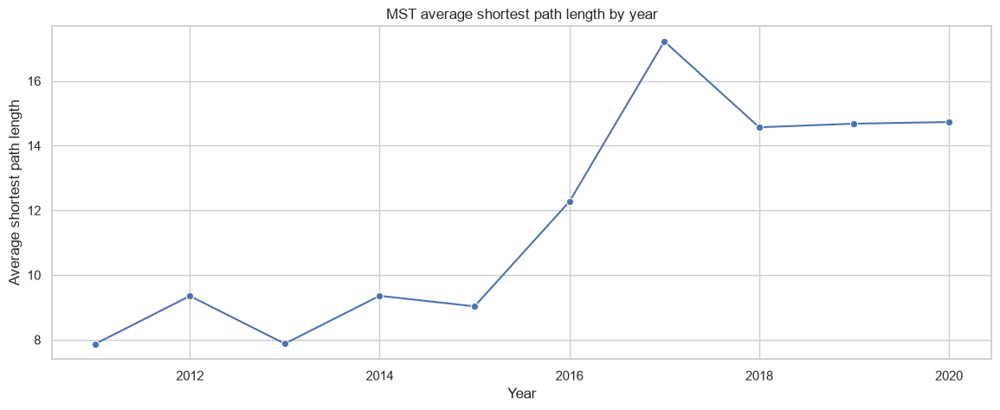

In [9]:
avg_path = pd.Series({y: nx.average_shortest_path_length(g) for y, g in mst_by_year.items()},
                     name='average_shortest_path_length')

fig, ax = plt.subplots(figsize=(14, 5))
sns.lineplot(x=avg_path.index, y=avg_path.values, marker='o', ax=ax)
ax.set(xlabel='Year', ylabel='Average shortest path length',
       title='MST average shortest path length by year')
avg_path.to_frame()

## 5. Portfolio construction on the full 2011–2020 network
Build one MST from all ten years and score every stock on how central it is.

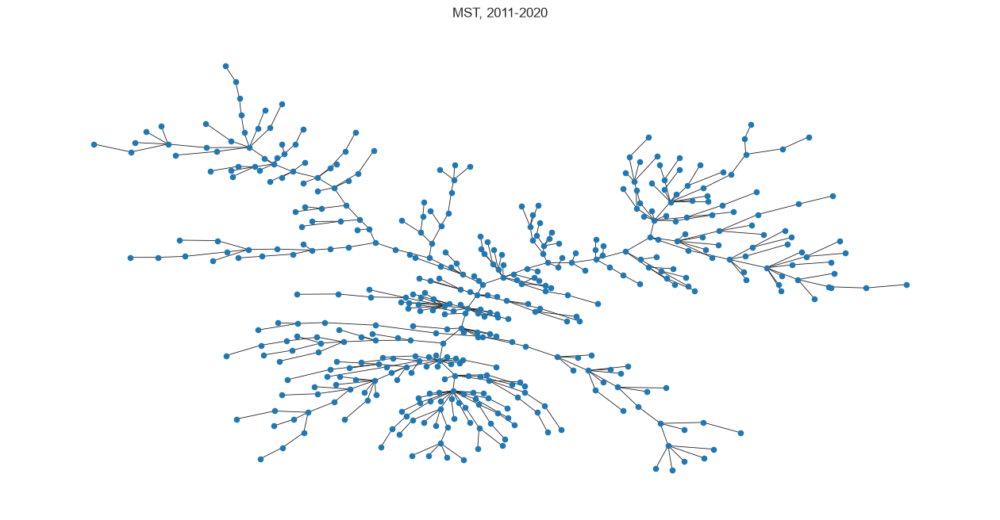

In [10]:
corr_full = returns.corr()
mst = build_mst(corr_full)

fig, ax = plt.subplots(figsize=(16, 8))
nx.draw_kamada_kawai(mst, ax=ax, with_labels=False, node_size=20, width=0.6)
ax.set_title('MST, 2011-2020');

### Centrality measures

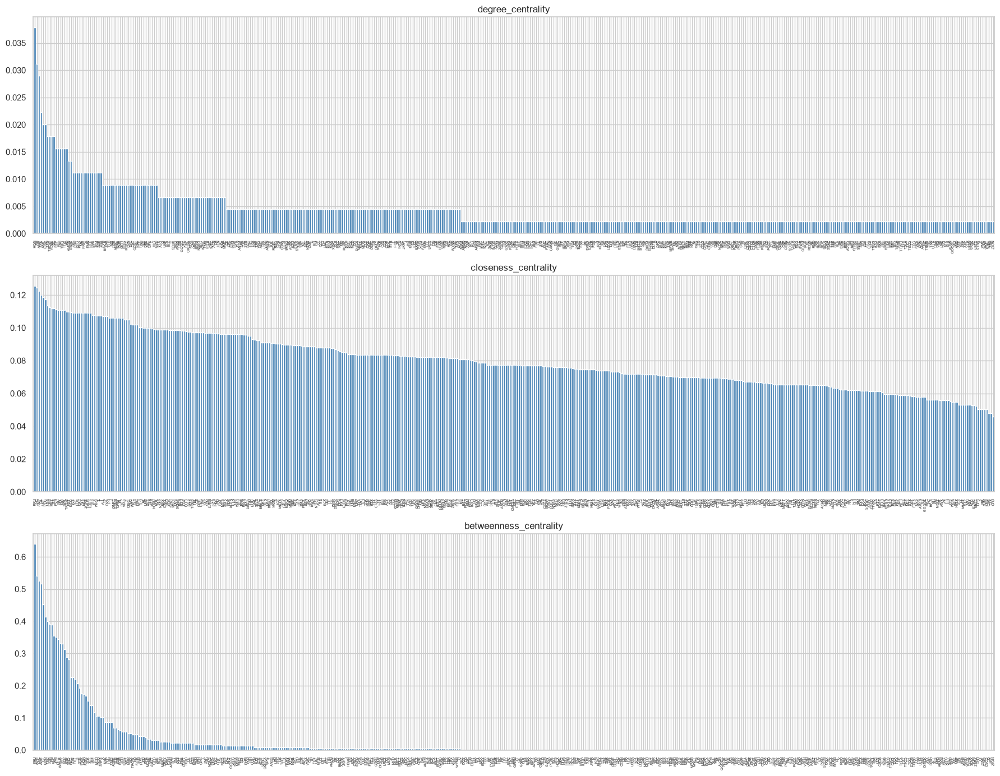

In [11]:
centrality = pd.DataFrame({
    'degree_centrality': nx.degree_centrality(mst),
    'closeness_centrality': nx.closeness_centrality(mst),
    'betweenness_centrality': nx.betweenness_centrality(mst),
})

fig, axes = plt.subplots(3, 1, figsize=(18, 14))
for ax, col in zip(axes, centrality.columns):
    centrality[col].sort_values(ascending=False).plot.bar(ax=ax, width=0.9, color='steelblue')
    ax.set_title(col)
    ax.set_xlabel('')
    ax.tick_params(axis='x', labelsize=4)
plt.tight_layout();

### Selection criteria
Following the paper, each stock gets five scores:

| Criterion | Meaning | Central = |
|---|---|---|
| Degree centrality | share of other stocks it is directly linked to | high |
| Betweenness centrality | how often it lies on shortest paths | high |
| Distance on degree | hops to the highest-degree stock | low |
| Distance on correlation | hops to the stock with the highest sum of correlations to its MST neighbours | low |
| Distance on distance | hops to the stock with the smallest mean hop distance to all others | low |

*Central score* = mean of degree and betweenness centrality. *Peripheral score* = mean of the three hop distances.

In [12]:
hops = dict(nx.all_pairs_shortest_path_length(mst))   # unweighted hop counts

# 1) hops to the node with the largest degree centrality
hub_degree = centrality['degree_centrality'].idxmax()

# 2) hops to the node with the highest sum of correlations to its MST neighbours
corr_sum = pd.Series({n: corr_full.loc[n, list(mst.neighbors(n))].sum() for n in mst.nodes})
hub_corr = corr_sum.idxmax()

# 3) hops to the node with the smallest mean hop distance to every other node
mean_hops = pd.Series({n: np.mean([d for m, d in hops[n].items() if m != n]) for n in mst.nodes})
hub_dist = mean_hops.idxmin()

print('Hub (degree):', hub_degree, '| Hub (correlation):', hub_corr, '| Hub (distance):', hub_dist)

node_stats = centrality[['degree_centrality', 'betweenness_centrality']].copy()
node_stats['average_centrality'] = node_stats[['degree_centrality', 'betweenness_centrality']].mean(axis=1)
node_stats['distance_degree_criteria'] = pd.Series({n: hops[n][hub_degree] for n in mst.nodes})
node_stats['distance_correlation_criteria'] = pd.Series({n: hops[n][hub_corr] for n in mst.nodes})
node_stats['distance_distance_criteria'] = pd.Series({n: hops[n][hub_dist] for n in mst.nodes})
node_stats['average_distance'] = node_stats[['distance_degree_criteria',
                                              'distance_correlation_criteria',
                                              'distance_distance_criteria']].mean(axis=1)
node_stats.head()

Hub (degree): HON | Hub (correlation): HON | Hub (distance): PRU


,degree_centrality,betweenness_centrality,average_centrality,distance_degree_criteria,distance_correlation_criteria,distance_distance_criteria,average_distance
MMM,0.002227,0.000000,0.001114,2,2,7,3.666667
AOS,0.004454,0.022073,0.013264,6,6,5,5.666667
ABT,0.008909,0.056584,0.032746,9,9,8,8.666667
ABMD,0.002227,0.000000,0.001114,10,10,9,9.666667
ACN,0.006682,0.008899,0.007790,16,16,9,13.666667


### Select the portfolios

In [13]:
central_portfolio = node_stats.nlargest(N_STOCKS, 'average_centrality').index.tolist()
peripheral_portfolio = node_stats.nlargest(N_STOCKS, 'average_distance').index.tolist()

print('Central   :', central_portfolio)
print('Peripheral:', peripheral_portfolio)
print('Overlap   :', set(central_portfolio) & set(peripheral_portfolio))

Central   : ['PRU', 'AMP', 'LNC', 'AME', 'GL', 'PH', 'EMR', 'TFC', 'USB', 'PNC', 'JPM', 'PFG', 'BRK-B', 'HST', 'ADP']
Peripheral: ['CHD', 'CLX', 'CAG', 'CPB', 'HRL', 'SJM', 'K', 'KMB', 'MO', 'ABC', 'ATO', 'CL', 'STZ', 'EVRG', 'GIS']
Overlap   : set()


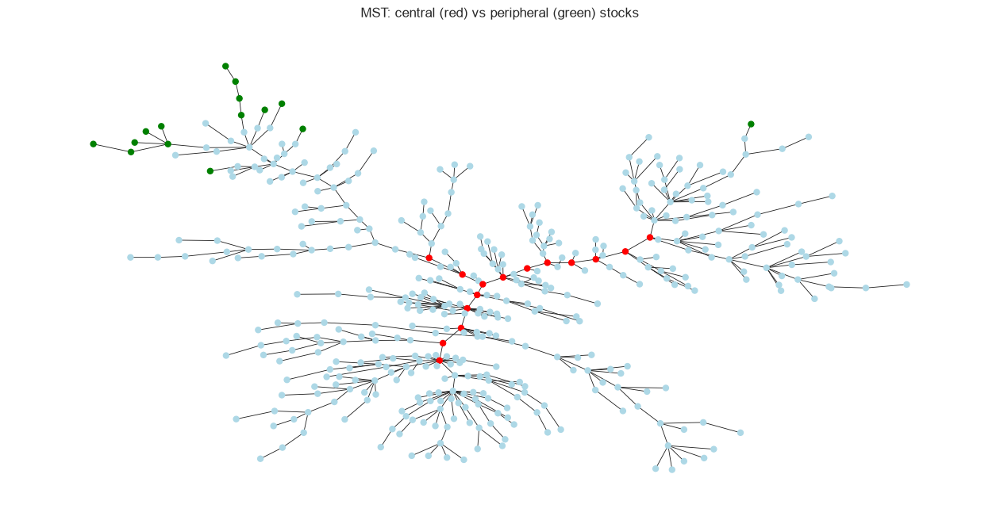

In [14]:
colors = ['red' if n in central_portfolio else 'green' if n in peripheral_portfolio else 'lightblue'
          for n in mst.nodes]

fig, ax = plt.subplots(figsize=(16, 8))
nx.draw_kamada_kawai(mst, ax=ax, with_labels=False, node_color=colors, node_size=25, width=0.6)
ax.set_title('MST: central (red) vs peripheral (green) stocks');

## 6. Performance evaluation in 2021
Invest 100,000 equally across the stocks of each portfolio on the first trading day of 2021, buy and hold, and compare with the S&P 500 index.

In [15]:
def load_sp500_2021():
    """S&P 500 index level for 2021 (FRED series SP500), cached locally after the first download."""
    if SP500_CACHE.exists():
        raw = pd.read_csv(SP500_CACHE, index_col=0, parse_dates=True)
    else:
        raw = pd.read_csv(FRED_URL, index_col=0, parse_dates=True)
        raw.loc['2021-01-01':'2021-12-31'].to_csv(SP500_CACHE)
    s = pd.to_numeric(raw.iloc[:, 0], errors='coerce').rename('sp500')
    return s.loc['2021-01-01':'2021-12-31'].dropna()

sp500 = load_sp500_2021()
sp500.head()

observation_date
2021-01-04    3700.65
2021-01-05    3726.86
2021-01-06    3748.14
2021-01-07    3803.79
2021-01-08    3824.68
Name: sp500, dtype: float64

In [16]:
def portfolio_value(price_df, tickers, amount):
    """Buy-and-hold value of an equal-dollar basket, starting at `amount` on the first row."""
    basket = price_df[tickers].ffill()
    shares = (amount / len(tickers)) / basket.iloc[0]
    return (basket * shares).sum(axis=1)

# The 2021 CSV starts on 2020-12-31; start trading on the first 2021 session
prices_2021 = prices_2021.loc['2021-01-01':]

all_portfolios = pd.DataFrame({
    'S&P 500': sp500 * (INVESTMENT / sp500.iloc[0]),
    'Central portfolio': portfolio_value(prices_2021, central_portfolio, INVESTMENT),
    'Peripheral portfolio': portfolio_value(prices_2021, peripheral_portfolio, INVESTMENT),
}).dropna()

all_portfolios.head()

,S&P 500,Central portfolio,Peripheral portfolio
2021-01-04,100000.000000,100000.000000,100000.000000
2021-01-05,100708.253955,100367.539642,99939.498828
2021-01-06,101283.288071,104903.500933,100698.210020
2021-01-07,102787.077946,105830.016412,99868.395772
2021-01-08,103351.573372,105499.869692,99649.155774


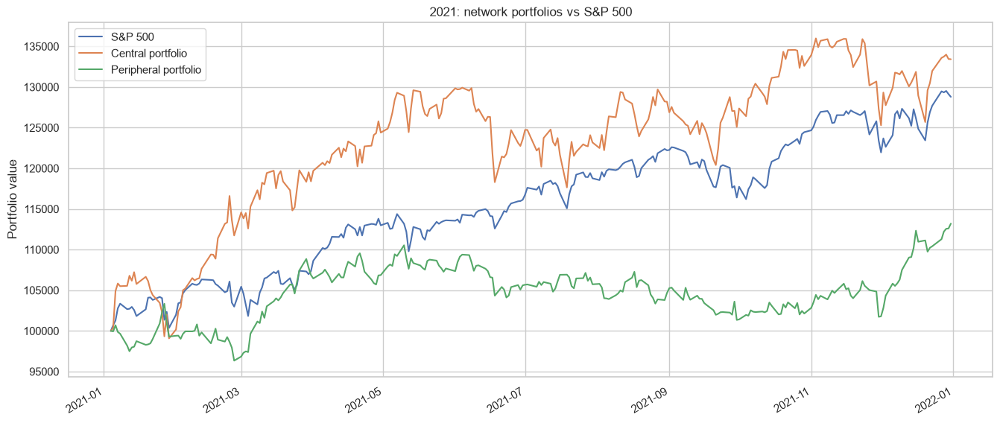

In [17]:
fig, ax = plt.subplots(figsize=(16, 7))
all_portfolios.plot(ax=ax)
ax.set(ylabel='Portfolio value', xlabel='', title='2021: network portfolios vs S&P 500')
ax.legend(loc='upper left');

In [18]:
def summary(values):
    ret = values.pct_change().dropna()
    return pd.Series({
        'Final value': values.iloc[-1],
        'Total return %': (values.iloc[-1] / values.iloc[0] - 1) * 100,
        'Annualised volatility %': ret.std() * np.sqrt(252) * 100,
        'Max drawdown %': ((values / values.cummax()) - 1).min() * 100,
    })

all_portfolios.apply(summary).T.round(2)

,Final value,Total return %,Annualised volatility %,Max drawdown %
S&P 500,128793.05,28.79,13.03,-5.21
Central portfolio,133418.70,33.42,20.91,-9.44
Peripheral portfolio,113195.39,13.20,12.84,-8.31
